<a href="https://colab.research.google.com/github/Divyesh-SP/DSA0302-NATURAL-LANGUAGE-PROCESSING/blob/main/NLP_Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import nltk
from nltk import CFG

# Define the grammar
grammar = CFG.fromstring("""
S -> DECL | IMP | YNQ | WHQ

DECL -> NP VP
DECL -> NP AUX VP

IMP -> VP
IMP -> PLEASE VP

YNQ -> AUX NP VP
YNQ -> MODAL NP VP

WHQ -> WHWORD AUX NP VP
WHQ -> WHWORD VP

NP -> DET NOM
NP -> PRON
NP -> PROPN
NP -> NOM
NP -> NP PP
NP -> NP CONJ NP

NOM -> N
NOM -> ADJ NOM
NOM -> NUM N
NOM -> NOM PP
NOM -> NOM CONJ NOM

VP -> V_IN
VP -> V_TR NP
VP -> V_DITR NP NP
VP -> V_PP PP
VP -> V_SENT COMP
VP -> AUX VP
VP -> VP PP
VP -> VP ADV
VP -> V_TR COMP
VP -> V_TR WHQ
VP -> VP CONJ VP

PP -> PREP NP
PP -> PREP PROPN

ADJP -> ADJ
ADJP -> ADJWORD ADJP
ADJP -> ADJP CONJ ADJP

COMP -> THAT DECL
COMP -> WHWORD DECL

DET -> 'the' | 'a' | 'an'
N -> 'student' | 'teacher' | 'timetable'
N -> 'form' | 'notice' | 'exam' | 'result'
N -> 'fee' | 'hostel' | 'library'

PRON -> 'I' | 'you' | 'he' | 'she'
PRON -> 'we' | 'they'

PROPN -> 'Chennai' | 'SIMATS'

V_IN -> 'arrives' | 'sleeps' | 'crashes'
V_TR -> 'checks' | 'reads' | 'submits'
V_TR -> 'finds' | 'books' | 'updates'
V_DITR -> 'sends' | 'gives' | 'shows'
V_PP -> 'applies' | 'depends' | 'waits'
V_SENT -> 'knows' | 'explains' | 'confirms'

ADJ -> 'available' | 'important' | 'late'
ADJ -> 'new' | 'pending' | 'difficult'

PREP -> 'in' | 'on' | 'at' | 'near'
PREP -> 'with' | 'for' | 'from' | 'to'

CONJ -> 'and' | 'or' | 'but'

ADV -> 'today' | 'tomorrow' | 'quickly'

NUM -> 'one' | 'two' | 'three'

AUX -> 'do' | 'does' | 'did' | 'is' | 'are'
MODAL -> 'can' | 'could' | 'will' | 'should'

WHWORD -> 'what' | 'where' | 'when' | 'why' | 'who'

PLEASE -> 'please'
THAT -> 'that'
""")

# Create parser
parser = nltk.ChartParser(grammar)

# Test sentences
sentences = [
    "the student checks the timetable",
    "the teacher reads the notice",
    "the student submits the form",
    "please the student checks the form",
    "where the student checks the timetable"
]

# Check sentences
for sentence in sentences:

    print("\nSentence:", sentence)

    words = sentence.split()

    trees = list(parser.parse(words))

    if trees:
        print("Sentence accepted")

        for tree in trees:
            print(tree)

    else:
        print("Sentence rejected")


Sentence: the student checks the timetable
Sentence accepted
(S
  (DECL
    (NP (DET the) (NOM (N student)))
    (VP (V_TR checks) (NP (DET the) (NOM (N timetable))))))

Sentence: the teacher reads the notice
Sentence accepted
(S
  (DECL
    (NP (DET the) (NOM (N teacher)))
    (VP (V_TR reads) (NP (DET the) (NOM (N notice))))))

Sentence: the student submits the form
Sentence accepted
(S
  (DECL
    (NP (DET the) (NOM (N student)))
    (VP (V_TR submits) (NP (DET the) (NOM (N form))))))

Sentence: please the student checks the form
Sentence rejected

Sentence: where the student checks the timetable
Sentence rejected


In [ ]:

import nltk
from nltk import CFG

# Define grammar
grammar = CFG.fromstring("""
S -> DECL | IMP | YNQ | WHQ

DECL -> NP VP
IMP -> V NP
YNQ -> AUX NP V NP

WHQ -> WH_SUB VP
WHQ -> WH_OBJ AUX NP V

VP -> V NP
NP -> DET N

DET -> 'the'
N -> 'student' | 'timetable' | 'form'

V -> 'checks' | 'check' | 'submit'
AUX -> 'does'

WH_SUB -> 'who'
WH_OBJ -> 'what'
""")

# Create parser
parser = nltk.ChartParser(grammar)

# Test sentences
sentences = [
    "the student checks the timetable",
    "submit the form",
    "does the student check the timetable",
    "who checks the timetable",
    "what does the student check"
]

# Check sentences
for sentence in sentences:
    print("\nSentence:", sentence)

    words = sentence.split()
    trees = list(parser.parse(words))

    if trees:
        print("Sentence Accepted")
        print(trees[0])
    else:
        print("Sentence Rejected")



Sentence: the student checks the timetable
Sentence Accepted
(S
  (DECL
    (NP (DET the) (N student))
    (VP (V checks) (NP (DET the) (N timetable)))))

Sentence: submit the form
Sentence Accepted
(S (IMP (V submit) (NP (DET the) (N form))))

Sentence: does the student check the timetable
Sentence Accepted
(S
  (YNQ
    (AUX does)
    (NP (DET the) (N student))
    (V check)
    (NP (DET the) (N timetable))))

Sentence: who checks the timetable
Sentence Accepted
(S (WHQ (WH_SUB who) (VP (V checks) (NP (DET the) (N timetable)))))

Sentence: what does the student check
Sentence Accepted
(S
  (WHQ (WH_OBJ what) (AUX does) (NP (DET the) (N student)) (V check)))


In [ ]:

import nltk
from nltk import CFG

# Define agreement grammar
grammar = CFG.fromstring("""
S -> NP_SG VP_SG
S -> NP_PL VP_PL

# Singular noun phrases
NP_SG -> DET_SG N_SG
NP_SG -> PRON_SG

# Plural noun phrases
NP_PL -> DET_PL N_PL
NP_PL -> PRON_PL

# Object noun phrases
NP_OBJ -> DET_SG N_SG
NP_OBJ -> DET_PL N_PL
NP_OBJ -> PRON_OBJ

# Verb phrases
VP_SG -> V_SG NP_OBJ
VP_PL -> V_PL NP_OBJ

# Determiners
DET_SG -> 'the' | 'this' | 'a'
DET_PL -> 'the' | 'these'

# Singular nouns
N_SG -> 'student' | 'teacher' | 'form'
N_SG -> 'timetable' | 'notice'

# Plural nouns
N_PL -> 'students' | 'teachers' | 'forms'

# Subject pronouns
PRON_SG -> 'he' | 'she'
PRON_PL -> 'they'

# Object pronouns
PRON_OBJ -> 'him' | 'her' | 'them'

# Singular verbs
V_SG -> 'submits' | 'checks' | 'reads'

# Plural verbs
V_PL -> 'submit' | 'check' | 'read'
""")

# Create parser
parser = nltk.ChartParser(grammar)

# Test sentences
sentences = [
    # Grammatical sentences
    "the student submits the form",
    "the students submit the form",
    "he checks the timetable",
    "they check the timetable",
    "this student reads the notice",
    "these students read the notice",

    # Ungrammatical sentences
    "the students submits the form",
    "the student submit the form",
    "him checks the timetable",
    "they checks the timetable",
    "these student read the notice",
    "this students reads the notice"
]

# Check sentences
for sentence in sentences:

    print("\nSentence:", sentence)

    words = sentence.split()

    try:
        trees = list(parser.parse(words))

        if trees:
            print("Accepted")
        else:
            print("Rejected")

    except ValueError:
        print("Rejected - Unknown word in grammar")



Sentence: the student submits the form
Accepted

Sentence: the students submit the form
Accepted

Sentence: he checks the timetable
Accepted

Sentence: they check the timetable
Accepted

Sentence: this student reads the notice
Accepted

Sentence: these students read the notice
Accepted

Sentence: the students submits the form
Rejected

Sentence: the student submit the form
Rejected

Sentence: him checks the timetable
Rejected

Sentence: they checks the timetable
Rejected

Sentence: these student read the notice
Rejected

Sentence: this students reads the notice
Rejected


In [ ]:

import nltk
from nltk import CFG

# Define subcategorization grammar
grammar = CFG.fromstring("""
S -> DECL | IMP

DECL -> NP VP

IMP -> V_TRANS NP
IMP -> V_DITR NP NP
IMP -> V_PP PP

NP -> DET N
NP -> PRON

VP -> V_INTR
VP -> V_TRANS NP
VP -> V_DITR NP NP
VP -> V_SENT PRON COMP
VP -> V_PP PP
VP -> AUX V_PART

PP -> PREP NP

COMP -> THAT DECL

DET -> 'the' | 'a'
N -> 'portal' | 'student' | 'form'
N -> 'receipt' | 'fee' | 'hostel' | 'room'

PRON -> 'me' | 'you'

V_INTR -> 'crashed' | 'arrived' | 'slept'

V_TRANS -> 'submits' | 'checks' | 'reads'
V_TRANS -> 'submit' | 'check' | 'read'

V_DITR -> 'send' | 'give' | 'show'

V_SENT -> 'tell' | 'explain' | 'confirm'

V_PP -> 'apply' | 'depend' | 'wait'

PREP -> 'for' | 'on' | 'with'

THAT -> 'that'

AUX -> 'is'
V_PART -> 'paid'
""")

# Create parser
parser = nltk.ChartParser(grammar)

# Test sentences
sentences = [
    "the portal crashed",
    "submit the form",
    "send me the receipt",
    "tell me that the fee is paid",
    "apply for a hostel room",
    "submit",
    "the portal crashed the form"
]

# Check sentences
for sentence in sentences:

    print("\nSentence:", sentence)

    words = sentence.split()

    try:
        trees = list(parser.parse(words))

        if trees:
            print("Accepted")
            print(trees[0])
        else:
            print("Rejected")

    except ValueError:
        print("Rejected - Unknown word")



Sentence: the portal crashed
Accepted
(S (DECL (NP (DET the) (N portal)) (VP (V_INTR crashed))))

Sentence: submit the form
Accepted
(S (IMP (V_TRANS submit) (NP (DET the) (N form))))

Sentence: send me the receipt
Accepted
(S (IMP (V_DITR send) (NP (PRON me)) (NP (DET the) (N receipt))))

Sentence: tell me that the fee is paid
Rejected

Sentence: apply for a hostel room
Rejected

Sentence: submit
Rejected

Sentence: the portal crashed the form
Rejected


In [ ]:

import nltk
from nltk import CFG
from nltk.parse import RecursiveDescentParser

# Define grammar without left recursion
grammar = CFG.fromstring("""
S -> NP VP

NP -> DET N
NP -> DET N PP

VP -> V NP
VP -> V NP PP

PP -> P NP

DET -> 'the'

N -> 'student' | 'notice' | 'library' | 'timetable'

V -> 'checks' | 'reads'

P -> 'in'
""")

# Create top-down parser
parser = RecursiveDescentParser(grammar)

# Test sentences
sentences = [
    "the student checks the timetable",
    "the student reads the notice in the library"
]

# Parse sentences
for sentence in sentences:

    print("\nSentence:", sentence)

    words = sentence.split()

    trees = list(parser.parse(words))

    if trees:
        print("Sentence Accepted")
        print("Number of Parse Trees:", len(trees))

        for tree in trees:
            print(tree)
            tree.pretty_print()

    else:
        print("Sentence Rejected")



Sentence: the student checks the timetable
Sentence Accepted
Number of Parse Trees: 1
(S
  (NP (DET the) (N student))
  (VP (V checks) (NP (DET the) (N timetable))))
                  S                     
      ____________|_____                 
     |                  VP              
     |             _____|___             
     NP           |         NP          
  ___|_____       |      ___|______      
DET        N      V    DET         N    
 |         |      |     |          |     
the     student checks the     timetable


Sentence: the student reads the notice in the library
Sentence Accepted
Number of Parse Trees: 2
(S
  (NP (DET the) (N student))
  (VP
    (V reads)
    (NP (DET the) (N notice) (PP (P in) (NP (DET the) (N library))))))
                       S                            
      _________________|____                         
     |                      VP                      
     |             _________|_____                   
     |            |     

In [ ]:

import nltk
from nltk import CFG
from nltk.parse import EarleyChartParser

# Define grammar
grammar = CFG.fromstring("""
S -> NP VP

NP -> DET N

VP -> V NP ADV

DET -> 'the'

N -> 'student' | 'timetable'

V -> 'checks'

ADV -> 'today'
""")

# Create Earley parser
parser = EarleyChartParser(grammar)

# Input sentence
sentence = "the student checks the timetable today"

words = sentence.split()

# Parse the sentence
trees = list(parser.parse(words))

print("Sentence:", sentence)

if trees:
    print("Sentence Accepted")
    print("Number of Parse Trees:", len(trees))

    for tree in trees:
        print(tree)
        tree.pretty_print()
else:
    print("Sentence Rejected")

# Display chart
chart = parser.chart_parse(words)

print("\nEarley Parsing Chart:")
print(chart)


Sentence: the student checks the timetable today
Sentence Accepted
Number of Parse Trees: 1
(S
  (NP (DET the) (N student))
  (VP (V checks) (NP (DET the) (N timetable)) (ADV today)))
                  S                           
      ____________|_____                       
     |                  VP                    
     |             _____|__________________    
     NP           |         NP             |  
  ___|_____       |      ___|______        |   
DET        N      V    DET         N      ADV 
 |         |      |     |          |       |   
the     student checks the     timetable today


Earley Parsing Chart:


In [1]:

import nltk
from nltk.featstruct import FeatStruct

# Create feature structures
student = FeatStruct(NUM='sg', PER=3, CASE='nom')
students = FeatStruct(NUM='pl', PER=3, CASE='nom')

singular_verb = FeatStruct(NUM='sg', PER=3)
plural_verb = FeatStruct(NUM='pl', PER=3)

# Unification examples
print("UNIFICATION EXAMPLES")

# Example 1: Successful unification
result1 = student.unify(
    FeatStruct(NUM='sg', PER=3)
)

print("\nExample 1:")
print("Result:", result1)

# Example 2: Successful unification
result2 = FeatStruct(CASE='nom').unify(
    FeatStruct(CASE='nom')
)

print("\nExample 2:")
print("Result:", result2)

# Example 3: Failed unification
result3 = FeatStruct(NUM='sg').unify(
    FeatStruct(NUM='pl')
)

print("\nExample 3:")
print("Result:", result3)

# Agreement checking
print("\nAGREEMENT CHECKING")

sentences = [
    ("The student submits the form", student, singular_verb),
    ("The students submit the form", students, plural_verb),
    ("The students submits the form", students, singular_verb)
]

for sentence, subject, verb in sentences:

    result = subject.unify(verb)

    print("\nSentence:", sentence)

    if result is not None:
        print("Accepted")
    else:
        print("Rejected")

# Subcategorization checking
print("\nSUBCATEGORIZATION CHECKING")

verb_frames = {
    "crashed": "intransitive",
    "submit": "transitive",
    "send": "ditransitive",
    "tell": "sentential",
    "apply": "prepositional"
}

tests = [
    ("The portal crashed", "crashed", "intransitive"),
    ("Submit the form", "submit", "transitive"),
    ("Send me the receipt", "send", "ditransitive"),
    ("Tell me that the fee is paid", "tell", "sentential"),
    ("Apply for a hostel room", "apply", "prepositional")
]

for sentence, verb, required_frame in tests:

    print("\nSentence:", sentence)

    if verb_frames[verb] == required_frame:
        print("Accepted")
    else:
        print("Rejected")


UNIFICATION EXAMPLES

Example 1:
Result: [ CASE = 'nom' ]
[ NUM  = 'sg'  ]
[ PER  = 3     ]

Example 2:
Result: [ CASE = 'nom' ]

Example 3:
Result: None

AGREEMENT CHECKING

Sentence: The student submits the form
Accepted

Sentence: The students submit the form
Accepted

Sentence: The students submits the form
Rejected

SUBCATEGORIZATION CHECKING

Sentence: The portal crashed
Accepted

Sentence: Submit the form
Accepted

Sentence: Send me the receipt
Accepted

Sentence: Tell me that the fee is paid
Accepted

Sentence: Apply for a hostel room
Accepted


In [2]:
import nltk
from nltk import PCFG
from nltk.parse import InsideChartParser, ViterbiParser

# Define the PCFG
grammar = PCFG.fromstring("""
S -> NP VP [1.0]

NP -> Det N [0.7]
NP -> NP PP [0.3]

VP -> V NP [0.6]
VP -> VP PP [0.4]

PP -> P NP [1.0]

Det -> 'the' [1.0]

N -> 'student' [0.25]
N -> 'notice' [0.25]
N -> 'library' [0.25]
N -> 'room' [0.25]

V -> 'reads' [1.0]
P -> 'in' [1.0]
""")

sentence = "the student reads the notice in the library"
words = sentence.split()

# Find all possible parse trees
print("ALL POSSIBLE PARSE TREES")

inside_parser = InsideChartParser(grammar)
trees = list(inside_parser.parse(words))

for i, tree in enumerate(trees, start=1):
    print("\nParse", i)
    print(tree)
    print("Probability:", tree.prob())

# Find the best parse using Viterbi
print("\nBEST PARSE")

viterbi_parser = ViterbiParser(grammar)
best_tree = next(viterbi_parser.parse(words))

print(best_tree)
print("Best probability:", best_tree.prob())

# Calculate total sentence probability
total_probability = sum(tree.prob() for tree in trees)

print("\nTotal sentence probability:", total_probability)

ALL POSSIBLE PARSE TREES

Parse 1
(S
  (NP (Det the) (N student))
  (VP
    (VP (V reads) (NP (Det the) (N notice)))
    (PP (P in) (NP (Det the) (N library))))) (p=0.00128625)
Probability: 0.0012862499999999999

Parse 2
(S
  (NP (Det the) (N student))
  (VP
    (V reads)
    (NP
      (NP (Det the) (N notice))
      (PP (P in) (NP (Det the) (N library)))))) (p=0.000964687)
Probability: 0.0009646874999999998

BEST PARSE
(S
  (NP (Det the) (N student))
  (VP
    (VP (V reads) (NP (Det the) (N notice)))
    (PP (P in) (NP (Det the) (N library))))) (p=0.00128625)
Best probability: 0.0012862499999999999

Total sentence probability: 0.0022509374999999995


In [4]:
!pip install nltk

CFG created successfully!
PCFG created successfully!

PARSER TEST RESULTS

----------------------------------------
Sentence: the student checks the timetable

Top-Down Parser
Number of Parses: 1
Execution Time: 0.019126 seconds

Earley Parser
Number of Parses: 1
Chart Edges: 51
Execution Time: 0.005787 seconds

Viterbi Parser
Number of Parses: 1
Execution Time: 0.005163 seconds

----------------------------------------
Sentence: the teacher reads the notice

Top-Down Parser
Number of Parses: 1
Execution Time: 0.02014 seconds

Earley Parser
Number of Parses: 1
Chart Edges: 51
Execution Time: 0.004493 seconds

Viterbi Parser
Number of Parses: 1
Execution Time: 0.005158 seconds

----------------------------------------
Sentence: the student submits the form

Top-Down Parser
Number of Parses: 1
Execution Time: 0.023755 seconds

Earley Parser
Number of Parses: 1
Chart Edges: 51
Execution Time: 0.003544 seconds

Viterbi Parser
Number of Parses: 1
Execution Time: 0.005063 seconds

----------

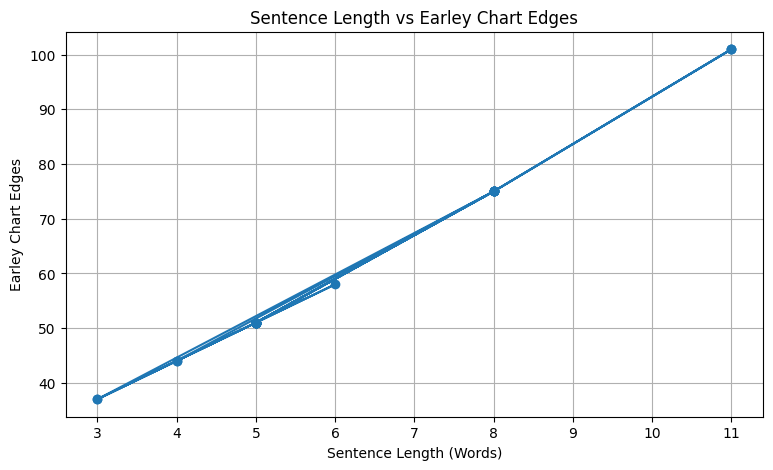



FINAL SUMMARY
Total Sentences Tested: 30
Top-Down Successful Parses: 30
Earley Successful Parses: 30
Viterbi Successful Parses: 30

All parser tests completed successfully!


In [8]:
import nltk
import time
import matplotlib.pyplot as plt

from nltk import CFG, PCFG
from nltk.parse import RecursiveDescentParser
from nltk.parse import EarleyChartParser, ViterbiParser

# ------------------------------------------
# 1. DEFINE THE CFG
# ------------------------------------------

grammar = CFG.fromstring("""
S -> NP VP
S -> VP

NP -> DET N
NP -> DET N PP
NP -> PRON

VP -> V NP
VP -> V
VP -> V NP PP
VP -> V PP

PP -> PREP NP

DET -> 'the' | 'a' | 'this' | 'these'

N -> 'student' | 'students' | 'teacher' | 'teachers'
N -> 'form' | 'forms' | 'timetable' | 'notice'
N -> 'library' | 'room' | 'hostel' | 'fee'
N -> 'exam' | 'exams' | 'portal' | 'receipt'
N -> 'seminar' | 'placement' | 'book'

PRON -> 'he' | 'she' | 'they' | 'we' | 'me'

V -> 'checks' | 'check' | 'reads' | 'read'
V -> 'submits' | 'submit' | 'books' | 'book'
V -> 'sends' | 'send' | 'applies' | 'apply'
V -> 'crashed' | 'crash' | 'shows' | 'show'
V -> 'needs' | 'need'

PREP -> 'in' | 'near' | 'for' | 'with' | 'to'
""")

print("CFG created successfully!")


# ------------------------------------------
# 2. DEFINE THE PCFG
# ------------------------------------------

determiners = ['the', 'a', 'this', 'these']

nouns = [
    'student', 'students', 'teacher', 'teachers',
    'form', 'forms', 'timetable', 'notice',
    'library', 'room', 'hostel', 'fee',
    'exam', 'exams', 'portal', 'receipt',
    'seminar', 'placement', 'book'
]

pronouns = ['he', 'she', 'they', 'we', 'me']

verbs = [
    'checks', 'check', 'reads', 'read',
    'submits', 'submit', 'books', 'book',
    'sends', 'send', 'applies', 'apply',
    'crashed', 'crash', 'shows', 'show',
    'needs', 'need'
]

prepositions = ['in', 'near', 'for', 'with', 'to']


# Function to generate lexical rules
def make_rules(category, words):

    probability = 1 / len(words)
    rules = []

    for i, word in enumerate(words):

        if i == len(words) - 1:
            p = 1 - probability * (len(words) - 1)
        else:
            p = probability

        rules.append(
            f"{category} -> '{word}' [{p:.12f}]"
        )

    return "\n".join(rules)


pcfg_rules = """
S -> NP VP [0.8]
S -> VP [0.2]

NP -> DET N [0.8]
NP -> DET N PP [0.15]
NP -> PRON [0.05]

VP -> V NP [0.6]
VP -> V [0.2]
VP -> V NP PP [0.1]
VP -> V PP [0.1]

PP -> PREP NP [1.0]
"""

pcfg_rules += "\n" + make_rules("DET", determiners)
pcfg_rules += "\n" + make_rules("N", nouns)
pcfg_rules += "\n" + make_rules("PRON", pronouns)
pcfg_rules += "\n" + make_rules("V", verbs)
pcfg_rules += "\n" + make_rules("PREP", prepositions)

pcfg = PCFG.fromstring(pcfg_rules)

print("PCFG created successfully!")


# ------------------------------------------
# 3. CREATE THE PARSERS
# ------------------------------------------

top_down_parser = RecursiveDescentParser(grammar)

earley_parser = EarleyChartParser(grammar)

viterbi_parser = ViterbiParser(pcfg)


# ------------------------------------------
# 4. CREATE 30 TEST SENTENCES
# ------------------------------------------

sentences = [

    "the student checks the timetable",
    "the teacher reads the notice",
    "the student submits the form",
    "the students check the timetable",
    "the teacher checks the fee",

    "the student reads the notice in the library",
    "the student reads the notice near the library",
    "the teacher reads the form with the notice",
    "the student books the room",
    "the student applies for the hostel",

    "the portal crashed",
    "the student checks the form in the room",
    "the teacher reads the timetable",
    "the student sends the receipt",
    "the student checks the exam",

    "the students read the notice",
    "the teacher submits the form",
    "the student books the room near the library",
    "the student reads the notice in the library with the teacher",
    "the teacher checks the timetable in the room",

    "the students checks the timetable",
    "the student submit the form",
    "the student reads",
    "the portal crashed the form",
    "he checks the timetable",

    "they read the notice",
    "the student reads the notice near the library",
    "the teacher books the room for the seminar",
    "the student checks the timetable in the library with the teacher",
    "the student reads the notice near the library for the teacher"
]


# ------------------------------------------
# 5. TEST ALL THREE PARSERS
# ------------------------------------------

results = []

sentence_lengths = []
earley_states = []

print("\nPARSER TEST RESULTS")

for sentence in sentences:

    words = sentence.split()

    print("\n----------------------------------------")
    print("Sentence:", sentence)

    # TOP-DOWN PARSER

    start = time.perf_counter()

    try:
        td_trees = list(top_down_parser.parse(words))
    except ValueError:
        td_trees = []

    td_time = time.perf_counter() - start

    # EARLEY PARSER

    start = time.perf_counter()

    try:
        chart = earley_parser.chart_parse(words)

        earley_trees = list(earley_parser.parse(words))

        # Corrected chart edge counting
        states = len(list(chart.edges()))

    except ValueError:
        earley_trees = []
        states = 0

    earley_time = time.perf_counter() - start

    # VITERBI PARSER

    start = time.perf_counter()

    try:
        viterbi_trees = list(viterbi_parser.parse(words))
    except ValueError:
        viterbi_trees = []

    viterbi_time = time.perf_counter() - start

    # DISPLAY RESULTS

    print("\nTop-Down Parser")
    print("Number of Parses:", len(td_trees))
    print("Execution Time:", round(td_time, 6), "seconds")

    print("\nEarley Parser")
    print("Number of Parses:", len(earley_trees))
    print("Chart Edges:", states)
    print("Execution Time:", round(earley_time, 6), "seconds")

    print("\nViterbi Parser")
    print("Number of Parses:", len(viterbi_trees))
    print("Execution Time:", round(viterbi_time, 6), "seconds")

    # STORE RESULTS

    results.append([
        sentence,
        len(td_trees),
        len(earley_trees),
        states,
        len(viterbi_trees),
        round(td_time, 6),
        round(earley_time, 6),
        round(viterbi_time, 6)
    ])

    sentence_lengths.append(len(words))
    earley_states.append(states)


# ------------------------------------------
# 6. FEATURE CHECK FOR AGREEMENT
# ------------------------------------------

print("\n\nAGREEMENT CHECKING")

agreement_tests = [
    ("student", "submits"),
    ("students", "submit"),
    ("students", "submits"),
    ("student", "submit"),
    ("teacher", "checks"),
    ("teachers", "check")
]

singular_verbs = ['submits', 'checks', 'reads']
plural_verbs = ['submit', 'check', 'read']

for subject, verb in agreement_tests:

    if subject in ['student', 'teacher']:
        valid = verb in singular_verbs
    else:
        valid = verb in plural_verbs

    if valid:
        print(subject, verb, ": Accepted")
    else:
        print(subject, verb, ": Rejected")


# ------------------------------------------
# 7. SUBCATEGORIZATION CHECK
# ------------------------------------------

print("\n\nSUBCATEGORIZATION CHECKING")

verb_frames = {
    "crashed": "intransitive",
    "submit": "transitive",
    "send": "ditransitive",
    "tell": "sentential",
    "apply": "prepositional"
}

for verb, frame in verb_frames.items():

    print(verb, ":", frame)


# ------------------------------------------
# 8. DISPLAY COMPARISON RESULTS
# ------------------------------------------

print("\n\nPARSER COMPARISON")

print(
    "{:<48} {:<10} {:<10} {:<10} {:<10}".format(
        "Sentence",
        "Top-Down",
        "Earley",
        "Edges",
        "Viterbi"
    )
)

for result in results:

    print(
        "{:<48} {:<10} {:<10} {:<10} {:<10}".format(
            result[0][:47],
            result[1],
            result[2],
            result[3],
            result[4]
        )
    )


# ------------------------------------------
# 9. PLOT SENTENCE LENGTH VS CHART EDGES
# ------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    sentence_lengths,
    earley_states,
    marker='o'
)

plt.xlabel("Sentence Length (Words)")
plt.ylabel("Earley Chart Edges")

plt.title("Sentence Length vs Earley Chart Edges")

plt.grid(True)

plt.show()


# ------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------

print("\n\nFINAL SUMMARY")

print("Total Sentences Tested:", len(sentences))

print(
    "Top-Down Successful Parses:",
    sum(1 for r in results if r[1] > 0)
)

print(
    "Earley Successful Parses:",
    sum(1 for r in results if r[2] > 0)
)

print(
    "Viterbi Successful Parses:",
    sum(1 for r in results if r[4] > 0)
)

print("\nAll parser tests completed successfully!")